In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from math import factorial, e

In [2]:
def draw(x, y, color, marker=None, markersize=6, legend=True):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(x, y, linewidth=2, color=color, marker=marker, markersize=markersize)
    if legend:
        ax.legend()
    ax.grid(True, which="both", linestyle="--", linewidth=0.5, color='gray', alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

def letters(title, xlabel, ylabel):
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

Zadanie 1

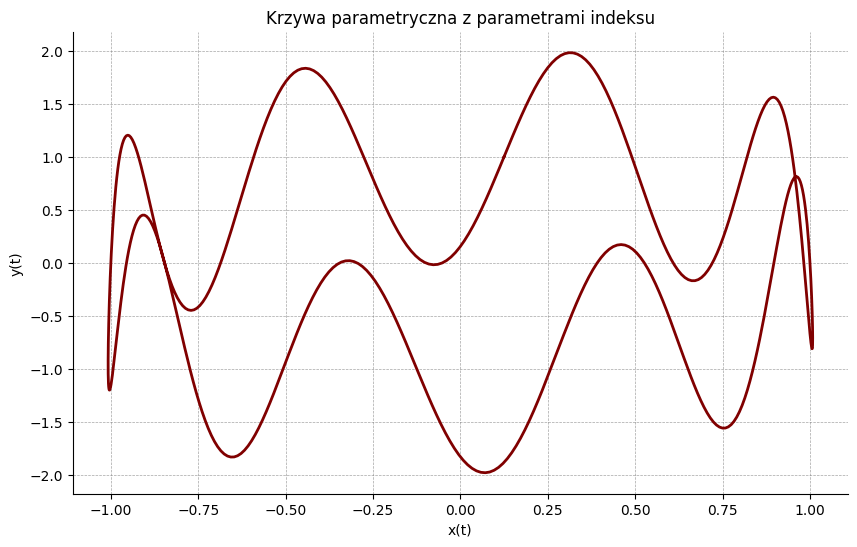

In [3]:
A = 1
B = 8

t = np.linspace(0, 2*np.pi, 500)

x = np.sin(t) + np.cos(A*t)/B
y = np.sin(B*t) + np.cos(A**2*t)

draw(x, y, 'maroon', legend=False)
letters('Krzywa parametryczna z parametrami indeksu', 'x(t)', 'y(t)')

Zadanie 2

In [235]:
def binom(n, k):
    if k == 0 or n == k:
        return 1
    return binom(n-1, k) + binom(n-1, k-1)

def times():
    ns = list(range(0, 31))
    times = []

    for n in ns:
        k = n // 2
        t0 = time.perf_counter()
        binom(n, k)
        t1 = time.perf_counter()
        times.append(t1 - t0)
    return ns, times
t = times()
    

In [236]:
def plot_binom_times(ns, times):
    draw(ns, times, 'purple', marker='*', markersize=10, legend=False)
    letters('Czas wykonania binom(n, n//2) dla n = 0..30', 'n', 'czas [s]')

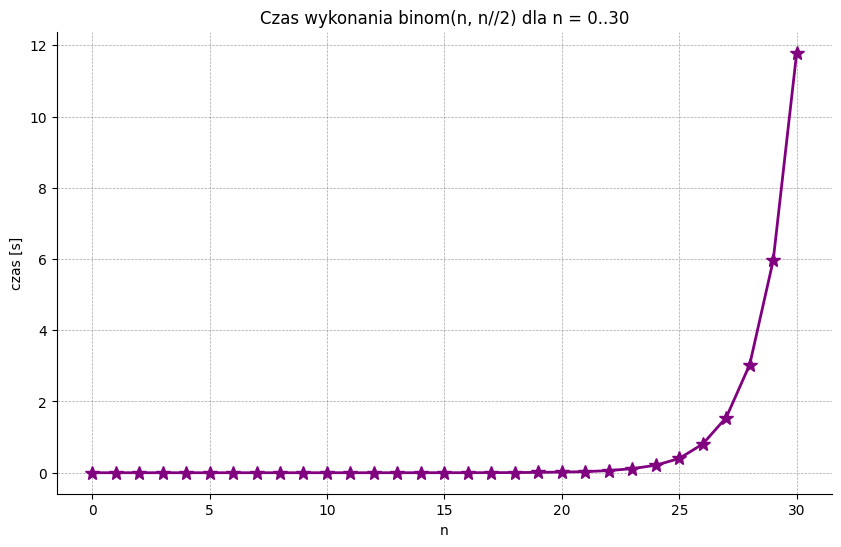

In [237]:
plot_binom_times(t[0], t[1])

Zadanie 3

In [118]:
def approx1(N):
    return sum(1/factorial(k) for k in range(0, N+1))

def approx2(N):
    s = sum((-1)**k / factorial(k) for k in range(0, N+1))
    return float('inf') if s == 0 else 1/s

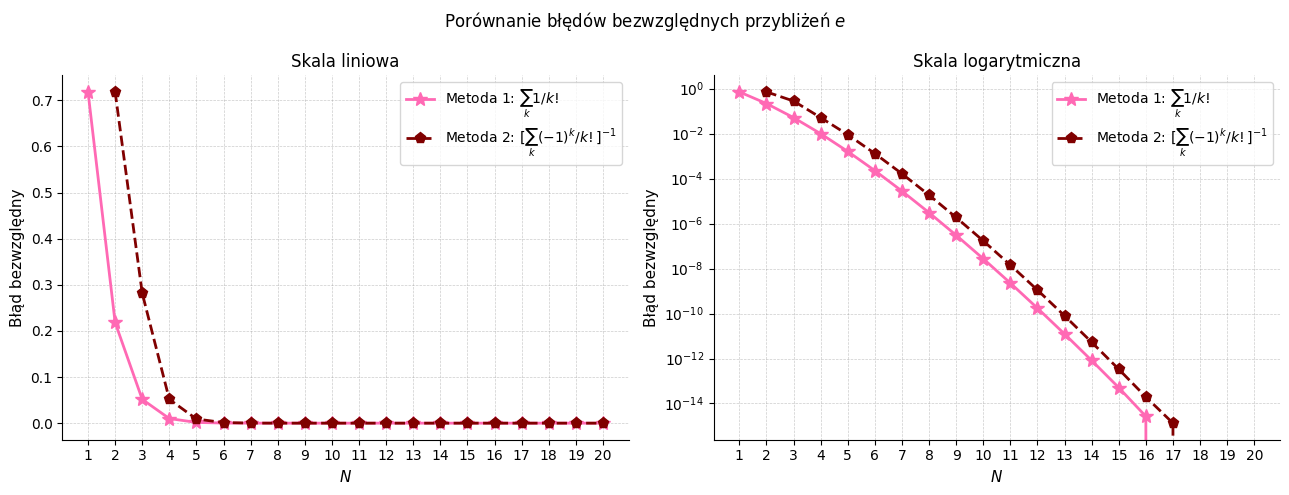

In [228]:
N_values = np.arange(1, 21)
err1 = np.array([abs(approx1(N) - e) for N in N_values])
err2 = np.array([abs(approx2(N) - e) for N in N_values])
 
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(
    "Porównanie błędów bezwzględnych przybliżeń $e$")
 
labels = [
    r"Metoda 1: $\sum_{k} 1/k!$",
    r"Metoda 2: $[\sum_{k} (-1)^k/k!]^{-1}$",
]
 
for ax, yscale in zip(axes, ["linear", "log"]):
    ax.plot(N_values, err1, "*-", color='hotpink', linewidth=2, markersize=10, label=labels[0])
    ax.plot(N_values, err2, "p--", color='maroon', linewidth=2, markersize=8, label=labels[1])
    ax.set_xlabel("$N$", fontsize=11)
    ax.set_ylabel("Błąd bezwzględny", fontsize=11)
    ax.set_title(f"Skala {'liniowa' if yscale == 'linear' else 'logarytmiczna'}")
    ax.set_yscale(yscale)
    ax.set_xticks(N_values)
    ax.legend()
    ax.grid(True, which="both", linestyle="--", linewidth=0.5, color='gray', alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

    

Zadanie 4

In [218]:
def draw_balances_data(data, years=20, scale='linear'):
    plt.figure(figsize=(10, 6))
    letters('Wzrost kapitału w czasie', 'Lata', 'Kapitał')
    
    for i in range(len(data)):
        perc = data[i][1]
        balance = data[i][0]
        balance_after = []
        for j in range(years+1):
            balance_after.append(balance * (1 + perc/100)**j)
        
        plt.plot(range(years+1), balance_after, color=[(0.2, 0.6, 0.8), (0.8, 0.2, 0.6)][i], label=f'{balance} PLN, {perc}% rocznie')
        plt.grid(True, which="both", linestyle="--", linewidth=0.5, color='gray', alpha=0.7)
        plt.yscale(scale)
        plt.legend()
        

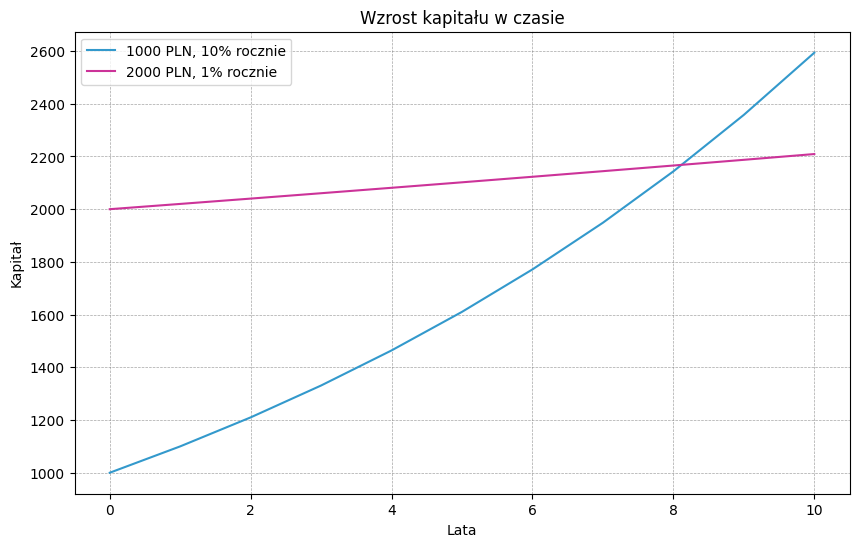

In [219]:
data = np.array([[1000, 10], [2000, 1]])
draw_balances_data(data, years=10)
